In [1]:
import gudhi
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np
import matplotlib
from math import cos, sin, pi, atan

import sys 
sys.path.append('../Code/')
import modules as mod



In [2]:
rect_m1 = mod.Rectangle((0,-1),(7,6),1)
rect_m2 = mod.Rectangle((0,3),(7,10),1)
M = mod.RectangleModule([rect_m1,rect_m2])
rect_n1 = mod.Rectangle((0,-1),(7,10),1)
rect_n2 = mod.Rectangle((0,3),(7,6),1)
N= mod.RectangleModule([rect_n1,rect_n2])
rect_o1 = mod.Rectangle((2,-1),(4,10),1)
rect_o2 = mod.Rectangle((0,4),(7,5),1)
O = mod.RectangleModule([rect_o1,rect_o2])


In [15]:
def plot_rectangle_module(M): 
    ## add coordinates of corners!!
    fig = plt.figure()
    ax = fig.add_subplot(111)
    ## rectangles 
    list_rectanlges = M.rectangles
    for i in range(len(list_rectanlges)):
        R = list_rectanlges[i]
        a = R.bottom_left 
        h= R.top_right[0]- a[0]
        v= R.top_right[1]- a[1]
        rectangle = matplotlib.patches.Rectangle(a,h,v,color ='C'+str(i), alpha = 0.2)
        ax.add_patch(rectangle)

    plt.xlim([-3, 15])
    plt.ylim([-3, 15])

    plt.title('Rectangle module')  
    plt.show()
    

    
def plot_weighted_bottleneck(M,N): 
    
    Crit_M = M.closure_lub() 
    Crit_N = N.closure_lub() 
    Crit_MN = list(set(Crit_M+Crit_N))
    Lines = []
    D = []
    k = 0
    Crit = []
    for i in range(len(Crit_MN)-1):
        p = Crit_MN[i]
        for j in range(i+1,len(Crit_MN)):
            q = Crit_MN[j] 
            line = mod.line_through_2points(Crit_MN[i], Crit_MN[j])
            if line.positive: 
                d = mod.compute_weighted_bottleneck(M,N,line)
                Lines.append(line)
                Crit.append([Crit_MN[i], Crit_MN[j]])
                D.append(d)
    print('There are {} lines through critical points'.format(len(Lines)))
    #print('Bottleneck distance for lines through critical points: ')
    #print(D)
    print('Maximum distance for lines:')
    print(max(D))
    
    ## computing bottlneck for "every" line
    
    Theta = np.linspace(0,pi/2,50)[1:-1]
    B = np.linspace(-5,5,50)
    D= np.zeros((len(Theta), len(B)))
    T = []
    BB= []
    Dist = []
    for t in range(len(Theta)): 
        for n in range(len(B)): 
            s = sin(Theta[t])
            c = cos(Theta[t])
            maxm = max(s,c)
            line = mod.Line((c/maxm, s/maxm), (B[n],-B[n]))
            d = mod.compute_weighted_bottleneck(M,N,line)
            D[t,n] = d
            T.append(Theta[t])
            BB.append(B[n])
            Dist.append(d)
    print('Maximum distance computed:')
    print(max(Dist))     
    plt.figure(figsize=(8,8))
    plt.scatter(T, BB, c= Dist,s = 10, cmap = "summer")
    
    ## plot markers for the lines through critical points
    b_crit = []
    theta_crit = []
    for j in range(len(Lines)):
        Line = Lines[j]
        b= Line.b[0]
        theta = atan(Line.m[1]/Line.m[0])
        b_crit.append(b)
        theta_crit.append(theta)
    
    for j in range(len(Lines)): 
        plt.scatter(theta_crit[j], b_crit[j], marker = 'x', color = 'black')
        #plt.text(theta_crit[j], b_crit[j], str(Crit[j]))
        
    ## plot titles
    plt.xlabel('theta')
    plt.ylabel('b')
    plt.title("Weighted bottleneck distance as a function of theta and b")
    plt.colorbar(label="Weighted distance", orientation="horizontal")
    plt.clim(0,max(Dist))
    plt.show()

There are 6 lines through critical points
Maximum distance for lines:
2.5454545454545454
Maximum distance computed:
2.458169677745382


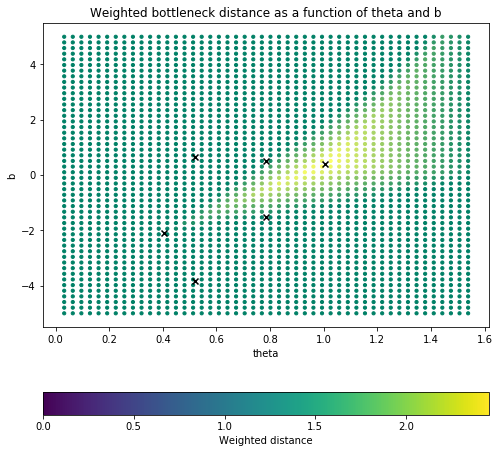

In [16]:
plot_weighted_bottleneck(M,N)

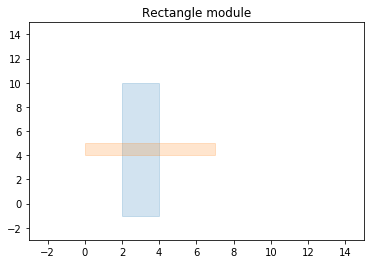

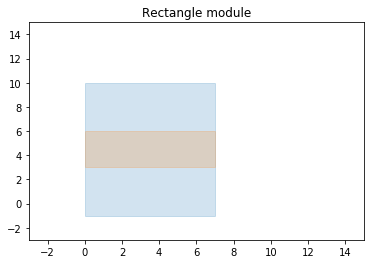

There are 61 lines through critical points
Maximum distance for lines:
3.0
Maximum distance computed:
3.0000000000000018


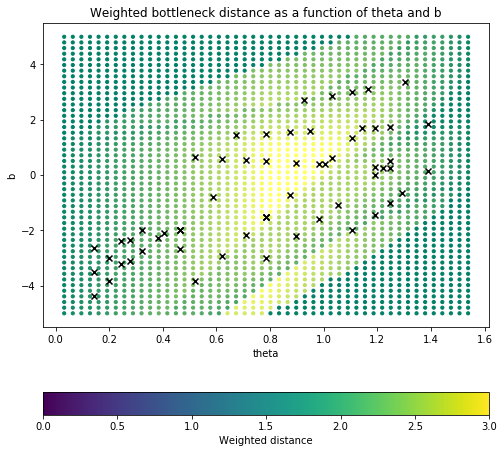

In [17]:
plot_rectangle_module(O)
plot_rectangle_module(N)
plot_weighted_bottleneck(O,N)


### make a bunch of random examples

In [18]:
r1 = mod.Rectangle((0,0),(4,6),1)
r2 = mod.Rectangle((2,3),(6,8),1)
r3=  mod.Rectangle((8,5),(10,9),1)
r4 = mod.Rectangle((0,3),(4,8),1)
r5 = mod.Rectangle((0,2),(7,6),1)
r6 = mod.Rectangle((4,7),(7,10),1)

In [20]:
R1 = mod.RectangleModule([r1])
R2 = mod.RectangleModule([r2])
R3 = mod.RectangleModule([r3])
R4 = mod.RectangleModule([r4])
R5 = mod.RectangleModule([r5])
R6 = mod.RectangleModule([r6])
R = [R1,R2,R3,R4,R5,R6]

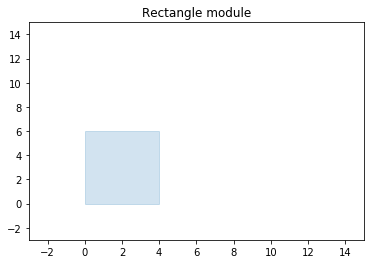

There are 1 lines through critical points
Maximum distance for lines:
1.4680012791765155e-308
Maximum distance computed:
2.145606934988218e-308


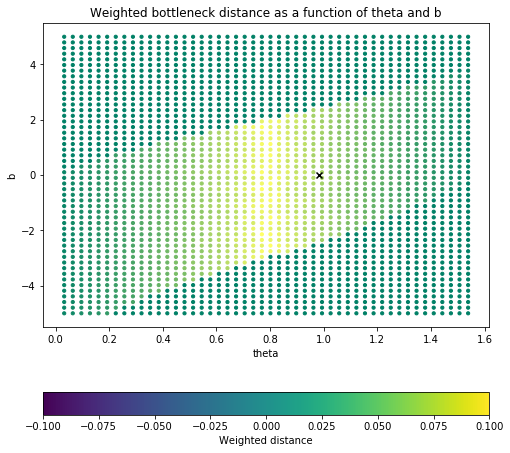

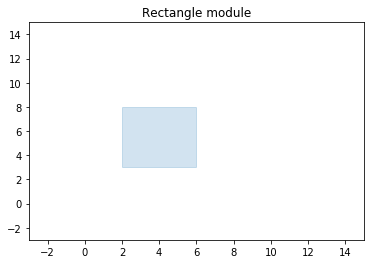

There are 12 lines through critical points
Maximum distance for lines:
2.0
Maximum distance computed:
2.4183673469387754


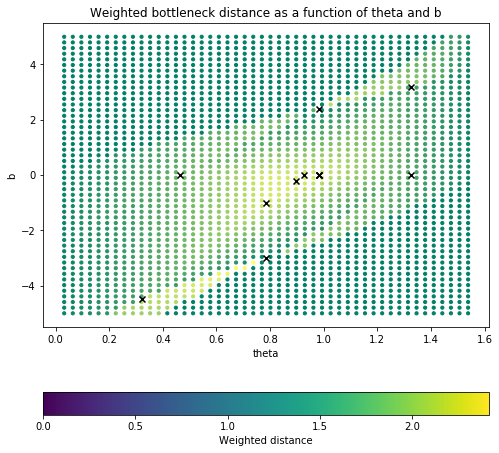

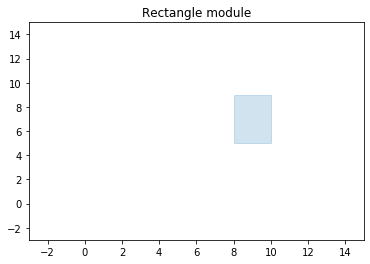

There are 14 lines through critical points
Maximum distance for lines:
3.888888888888889
Maximum distance computed:
3.9285714285714284


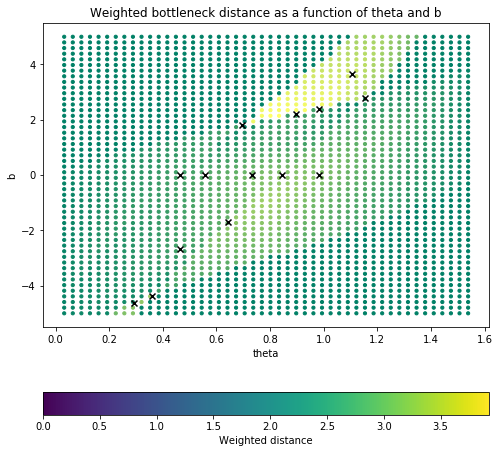

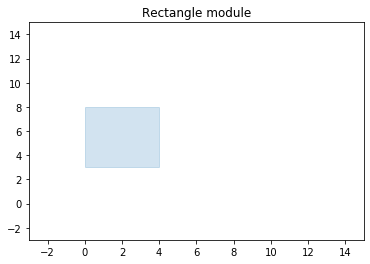

There are 6 lines through critical points
Maximum distance for lines:
2.142857142857143
Maximum distance computed:
2.4408791896919175


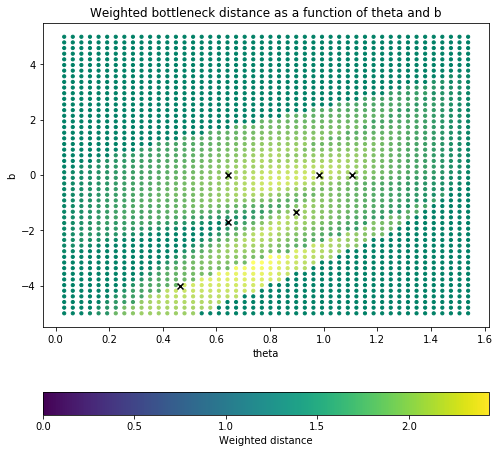

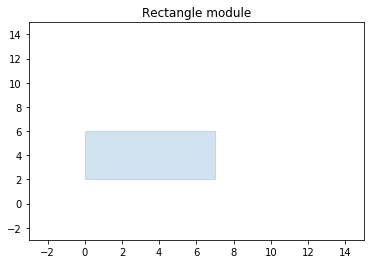

There are 7 lines through critical points
Maximum distance for lines:
2.1666666666666665
Maximum distance computed:
2.4285714285714284


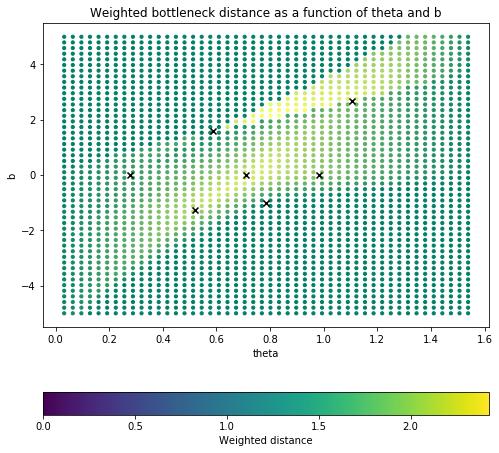

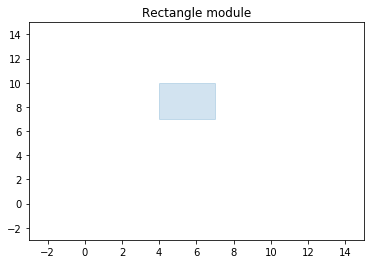

There are 14 lines through critical points
Maximum distance for lines:
3.090909090909091
Maximum distance computed:
3.4183673469387754


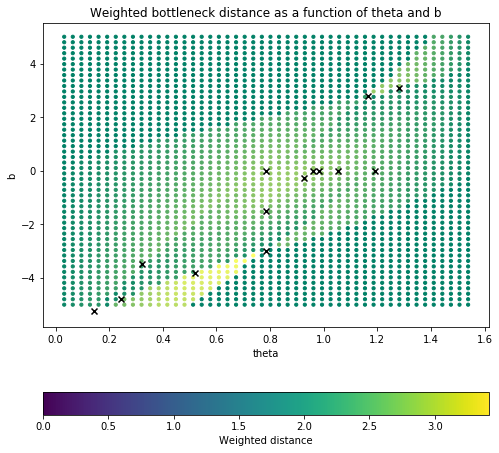

In [21]:
for i in range(len(R)): 
    plot_rectangle_module(R[i])
    plot_weighted_bottleneck(R[0],R[i])
    

### Todo: 
- plot the max distance with red cross
- compute for lines in closure of C_M U C_N 